# CVA, DVA and wrong-way risk

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 01 of this topic (the exposure of one swap)
- **Reading time:** about 50 minutes

**Question:** What does the default risk of the counterparty cost the bank on the four-swap netting set, how much of that number rests on the credit curve chosen, and how much does it grow when the counterparty is more likely to default exactly when it owes more?

## Objectives

By the end of this notebook you can:

- turn a credit spread into a survival curve and a default probability per bucket with the credit triangle;
- compute the unilateral CVA and DVA as a sum over time buckets, and say why the credit curve used here is a proxy;
- state the Hull and White hazard rate that depends on the portfolio value, and calibrate its time-dependent part sequentially;
- measure how much CVA changes with the wrong-way parameter $b$, and check that $b=0$ gives the independent CVA exactly;
- reproduce the three-path example of the paper's Appendix to its printed digits.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.ccr import cva
from riskvalidation.ccr import exposure as ex
from riskvalidation.ccr import hw1f
from riskvalidation.ccr import swaps as sw

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data are two variants of case C12 (counterparty credit risk): the uncollateralised netting set of four synthetic swaps, and the wrong-way-risk variant that adds the sweep over $b$. Both use the US Treasury curve of 2025-09-30 (licence class `mirror-allowed`).

- **Files read:** `data/derived/C12/netting-set.json` (curve, calibration, swaps, and the CVA block) and `data/derived/C12/wrong-way-risk.json` (the same book and the sweep over $b$).
- **The credit curve is a proxy.** The counterparty spread curve is the Treasury HQM corporate spot curve minus the Treasury zero curve of the same month end: an AAA-to-A market average, a floor for lower ratings and not the curve of any counterparty (research item R10). A negative spread would be set to zero and counted. The bank's own spread is a flat named parameter of 0.8% and both loss given default values are 60%, all labelled `convention`.
- **What is computed here:** the survival, the default probabilities and the CVA are recomputed from the committed spreads and the committed discounted expected exposure; the wrong-way sweep is recomputed from the simulation, which this notebook rebuilds.

The next cell loads both documents and prints the credit block.

In [2]:
# Load the two committed documents (three folders below the repository root) and print the credit block
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C12"
base_doc = json.loads((derived / "netting-set.json").read_text(encoding="utf-8"))
wwr_doc = json.loads((derived / "wrong-way-risk.json").read_text(encoding="utf-8"))
base, wwr = base_doc["outputs"], wwr_doc["outputs"]
credit = base["cva_dva"]

print("credit curve source:", credit["credit_curve_source"])
print("survival formula:", credit["survival_formula"],
      "| spreads floored at zero:", credit["spreads_floored_at_zero"])
print("LGD:", credit["lgd"], "| bank LGD:", credit["bank_lgd"],
      "| bank spread:", base["named_parameters"]["bank_spread"]["value"])
print("time buckets:", len(credit["buckets"]))
for b in credit["buckets"][:2] + credit["buckets"][-1:]:
    print(f"  [{b['t_start']:.3f}, {b['t_end']:.3f}] spread {b['spread']:.6f} | EPE {b['epe_discounted']:.0f}")

credit curve source: hqm-minus-treasury
survival formula: S(t) = exp(-s t / LGD) | spreads floored at zero: 0
LGD: 0.6 | bank LGD: 0.6 | bank spread: 0.008
time buckets: 33
  [0.000, 0.083] spread 0.001667 | EPE 12667
  [0.083, 0.167] spread 0.001667 | EPE 23970
  [9.000, 9.500] spread 0.006887 | EPE 36366


## Method

### Step 1: from a spread to a survival curve

For small default probabilities, the **credit triangle** says that the hazard rate is the spread divided by the loss given default, $\lambda = s/\mathrm{LGD}$, and survival to $t$ is $S(t) = e^{-s\,t/\mathrm{LGD}}$ (Hull and White, 2012, page 13). The default probability in a bucket is the fall of survival across it:

$$PD(t_{i-1}, t_i) = S(t_{i-1}) - S(t_i)$$

The engine's `survival_from_spread` and `default_probabilities` compute these. The spreads are read from the committed buckets. The next cell computes the survival and the default probabilities at three horizons.

In [3]:
# The survival curve and the bucket default probabilities from the spreads of the credit curve
buckets = credit["buckets"]
report = np.array([b["t_end"] for b in buckets])
times = np.concatenate([[0.0], report])
spreads = np.array([buckets[0]["spread"]] + [b["spread"] for b in buckets])
lgd, bank_lgd = credit["lgd"], credit["bank_lgd"]

survival = cva.survival_from_spread(spreads, times, lgd)
pd_cp = cva.default_probabilities(survival)
for years in (1.0, 5.0, 9.5):
    k = int(np.searchsorted(times, years - 1e-9))
    print(f"t = {years:4.1f} | spread {spreads[k]:.5f} | hazard s/LGD {spreads[k] / lgd:.5f}"
          f" | S(t) = {survival[k]:.5f} | 1 - S(t) = {1 - survival[k]:.5f}")
print("the bucket PD add up to 1 - S(T):", round(float(pd_cp.sum()), 8), "=", round(float(1 - survival[-1]), 8))

t =  1.0 | spread 0.00306 | hazard s/LGD 0.00509 | S(t) = 0.99492 | 1 - S(t) = 0.00508
t =  5.0 | spread 0.00512 | hazard s/LGD 0.00854 | S(t) = 0.95822 | 1 - S(t) = 0.04178
t =  9.5 | spread 0.00689 | hazard s/LGD 0.01148 | S(t) = 0.89669 | 1 - S(t) = 0.10331
the bucket PD add up to 1 - S(T): 0.10331047 = 0.10331047


The next cell draws the spread of the credit curve and the survival it implies, with the default probability of each bucket.

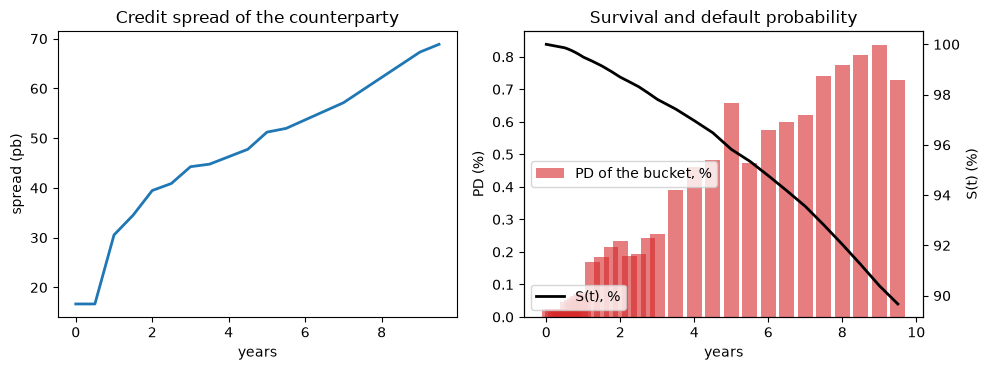

In [4]:
# Draw the spread curve (left) and the survival with the default probability of each bucket (right)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
left.plot(times, spreads * 1e4, color="tab:blue", lw=2)
left.set_xlabel("years")
left.set_ylabel("spread (pb)")
left.set_title("Credit spread of the counterparty")
right.bar(report, pd_cp * 100, width=0.4, color="tab:red", alpha=0.6, label="PD of the bucket, %")
right.set_xlabel("years")
right.set_ylabel("PD (%)")
twin = right.twinx()
twin.plot(times, survival * 100, color="black", lw=2, label="S(t), %")
twin.set_ylabel("S(t) (%)")
right.set_title("Survival and default probability")
right.legend(loc="center left")
twin.legend(loc="lower left")
fig.tight_layout()
plt.show()

The left panel shows a spread that rises from about 17 basis points at the short end to about 69 at nine and a half years, the shape of an investment-grade market average. The right panel turns it into survival, which falls smoothly to about 90% at the end of the grid, while the bars show that each half-year bucket carries a default probability that grows with time. What the panels do not show is any link to the swaps: so far the credit side is independent of the exposure, which is exactly the assumption the wrong-way model relaxes.

### Step 2: CVA and DVA

With the discounted expected positive exposure $\mathrm{EPE}(t_i)$ and negative exposure $\mathrm{ENE}(t_i)$ of notebook 01, and assuming exposure and default are independent (ORE methodology, the advanced discretisation):

$$\mathrm{CVA} = \sum_i PD(t_{i-1},t_i)\ \mathrm{LGD}\ \mathrm{EPE}(t_i), \qquad \mathrm{DVA} = \sum_i PD_{bank}(t_{i-1},t_i)\ \mathrm{LGD}_{bank}\ \mathrm{ENE}(t_i)$$

CVA is a positive cost and DVA a positive benefit; the simple bilateral value is $\mathrm{BCVA} = \mathrm{CVA} - \mathrm{DVA}$ (the first-to-default form is not implemented). The engine's `cva` and `dva` return the total and the bucket terms. The next cell computes both from the committed discounted profiles, and then replaces the proxy curve by a flat 125 bp spread, Hull and White's example value, to show how much the answer rests on the credit curve.

In [5]:
# CVA and DVA from the discounted profiles, and the CVA on a flat 125 bp spread
epe_d = np.array(base["exposure"]["ee_discounted"]["values"])
ene_d = np.array(base["exposure"]["ene_discounted"]["values"])
bank_spread = base["named_parameters"]["bank_spread"]["value"]
survival_bank = cva.survival_from_spread(np.full(times.size, bank_spread), times, bank_lgd)
pd_bank = cva.default_probabilities(survival_bank)

cva_value, cva_terms = cva.cva(epe_d, pd_cp, lgd)
dva_value, dva_terms = cva.dva(ene_d, pd_bank, bank_lgd)
flat_pd = cva.default_probabilities(cva.survival_from_spread(np.full(times.size, 0.0125), times, lgd))
cva_flat, flat_terms = cva.cva(epe_d, flat_pd, lgd)
zero_pd = cva.default_probabilities(cva.survival_from_spread(np.zeros(times.size), times, lgd))

print("CVA:", round(cva_value, 2), "| DVA:", round(dva_value, 2))
print("BCVA = CVA - DVA:", round(cva_value - dva_value, 2))
print("Monte Carlo error of the CVA:", round(credit["cva"]["mc_se"], 2))
print("share of the CVA from the first two years:",
      round(float(cva_terms[report <= 2.0].sum() / cva_value), 3))
print("the CVA is zero with a zero spread:", cva.cva(epe_d, zero_pd, lgd)[0])
print("CVA on a flat 125 bp spread:", round(cva_flat, 2),
      "| ratio to the credit curve:", round(cva_flat / cva_value, 2))

CVA: 9477.77 | DVA: 4344.1
BCVA = CVA - DVA: 5133.67
Monte Carlo error of the CVA: 51.05
share of the CVA from the first two years: 0.088
the CVA is zero with a zero spread: 0.0
CVA on a flat 125 bp spread: 16506.36 | ratio to the credit curve: 1.74


The next cell draws the CVA term of each time bucket under the credit curve of the case and under the flat 125 bp spread.

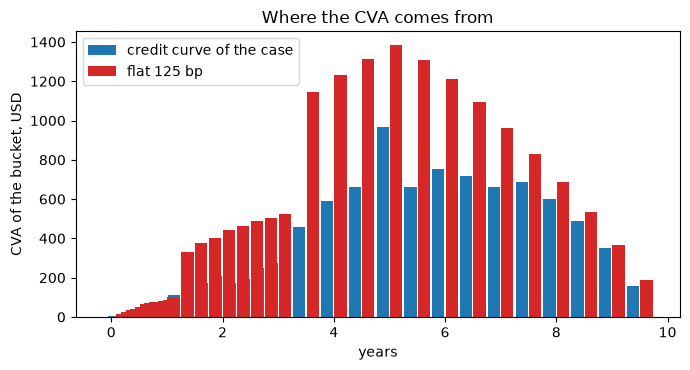

In [6]:
# Draw the CVA of each time bucket under the credit curve of the case and under a flat 125 bp spread
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(report - 0.12, cva_terms, width=0.22, color="tab:blue", label="credit curve of the case")
ax.bar(report + 0.12, flat_terms, width=0.22, color="tab:red", label="flat 125 bp")
ax.set_xlabel("years")
ax.set_ylabel("CVA of the bucket, USD")
ax.set_title("Where the CVA comes from")
ax.legend()
fig.tight_layout()
plt.show()

Each bar is the cost of defaults in one half-year bucket: the exposure of that bucket times the probability of defaulting in it, times the loss given default. The blue bars follow the shape of the exposure profile weighted by a slowly rising default probability, so the first two years contribute little; the red bars are higher everywhere because a flat 125 basis points is far above the case's curve at short maturities. The gap between the two colours is a difference in an input, the credit curve, and no amount of extra simulation would close it.

### Step 3: wrong-way risk, the Hull and White hazard rate

Wrong-way risk is the dependence between exposure and default: when the counterparty owes more, it is more likely to default. Hull and White (2012) model it by making the hazard rate depend on the value $w$ of the portfolio:

$$h(t) = \exp\big[a(t) + b\,w(t)\big]$$

A positive $b$ is wrong-way risk, a negative one right-way risk, and $b=0$ is independence. The function $a(t)$ is not free: it is calibrated, bucket after bucket, so that the average survival over the simulated paths equals the survival implied by the spread (equation of the paper's Appendix):

$$\frac{1}{m}\sum_{j=1}^{m} \exp\Big(-\sum_{i \le k} h_{ij}\,\Delta t_i\Big) = S(t_k)\qquad k = 1,\dots,n$$

so today's survival curve is reproduced whatever $b$ is, and only its distribution across the paths changes. The engine's `wwr_calibrate_a` solves it sequentially and returns $a$ and the hazards; `wwr_cva` computes the CVA on the paths, $\mathrm{LGD}\sum_i \overline{PD_{ij}\,E_{ij}}$. The value $w$ is in **USD million** and so is the unit of $b$. The next cell rebuilds the simulation of notebook 01 and prepares the three arrays the engine needs.

In [7]:
# Rebuild the paths of notebook 01; prepare the value in USD million and the discounted exposure
tenors = np.array([p["tenor_years"] for p in base["curve"]["points"]])
zeros = np.array([p["zero_rate"] for p in base["curve"]["points"]])
a, sigma = base["calibration_used"]["a"], base["calibration_used"]["sigma"]
p0, forward = hw1f.curve_functions(zeros, tenors)
named = base["named_parameters"]
swaps = [
    sw.Swap(t["trade_id"], t["notional"]["amount"], t["fixed_rate"], t["side"] == "payer",
            t["start_years"], t["maturity_years"], t["fixed_frequency_per_year"])
    for t in base["book"]["trades"]
]
closeouts = (14 / 360, 28 / 360)
merged = np.unique(np.round(np.concatenate([times] + [times + d for d in closeouts]), 12))
grid = sw.simulation_grid(merged, swaps)
r = hw1f.simulate_short_rate(grid, a, sigma, forward, named["path_count"]["value"], named["seed"]["value"])
numeraire = hw1f.bank_account(grid, r, a, sigma, p0, forward)
values = sw.swap_values_on_grid(swaps, grid, r, a, sigma, p0, forward)
ix = np.searchsorted(grid, report - sw.TIME_TOL)

v_net = ex.net_values(values[:, :, ix])
w = v_net / 1e6
x_disc = np.maximum(v_net, 0.0) / numeraire[:, ix]
dt = np.diff(times)
print("portfolio value w (paths, buckets):", w.shape,
      "| largest w in USD million:", round(float(w.max()), 4))
print("mean discounted exposure at 5 years:", round(float(x_disc.mean(axis=0)[9]), 1))

portfolio value w (paths, buckets): (20000, 33) | largest w in USD million: 2.0898
mean discounted exposure at 5 years: 81232.2


### Step 4: the CVA as a function of $b$

We compute the CVA for the same grid of $b$ as the committed variant (-2, 0, 1, 2 and 4 per USD million; the largest $|b|\,w$ is about 8, so the hazard is changed by a factor of $e^{8}$ on the most extreme path). The case calls `wwr_cva` at $b=0$ too: there the hazard does not depend on the path and the engine returns the independent CVA of step 2, bit for bit. The next cell prints the sweep, the check at $b=0$ and the calibration error, the largest gap between the average survival of the calibrated hazards and the target.

In [8]:
# The Hull-White CVA over the grid of b, with the calibration error of each hazard
sweep = []
print(f"{'b':>5s} {'CVA':>10s} {'vs b = 0':>9s} {'MC se':>8s} {'calibration error':>20s}")
for b in [row["b"] for row in wwr["wrong_way_risk"]["sweep"]]:
    value, se = cva.wwr_cva(w, x_disc, survival[1:], dt, lgd, b)
    _, h = cva.wwr_calibrate_a(w, survival[1:], dt, b)
    mean_survival = np.exp(-np.cumsum(h * dt[None, :], axis=1)).mean(axis=0)
    cal_err = float(np.max(np.abs(mean_survival - survival[1:])))
    sweep.append((b, value, se, h))
    print(f"{b:5.1f} {value:10.1f} {value / cva_value - 1:+9.1%} {se:8.1f} {cal_err:20.1e}")

b0 = [s for s in sweep if s[0] == 0.0][0]
print("b = 0 equals the independent CVA bit for bit:", "yes" if b0[1] == cva_value else "no")

    b        CVA  vs b = 0    MC se    calibration error
 -2.0     4755.9    -49.8%     18.7              1.0e-14
  0.0     9477.8     +0.0%     51.1              5.2e-13
  1.0    12439.6    +31.2%     83.2              6.8e-15
  2.0    15594.6    +64.5%    132.8              1.0e-14
  4.0    21706.8   +129.0%    276.0              8.8e-15
b = 0 equals the independent CVA bit for bit: yes


The next cell draws the CVA against $b$ with its Monte Carlo error, and the distribution of the calibrated hazard of the 5-year bucket across the paths for three values of $b$.

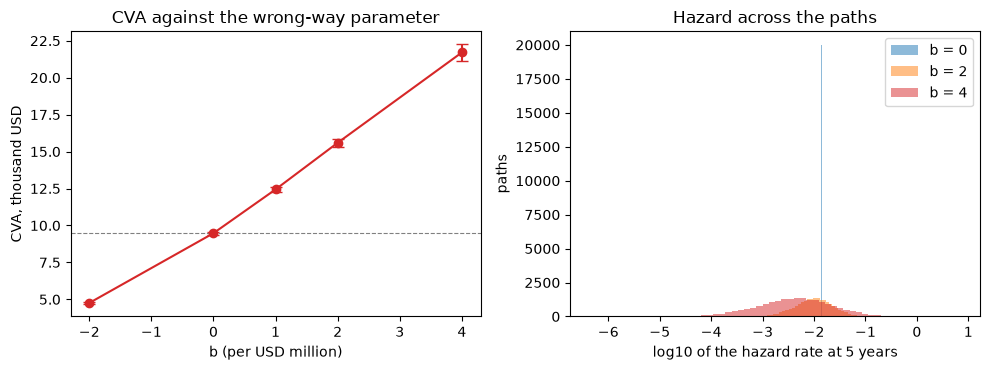

In [9]:
# Draw the CVA against b (left) and the 5-year hazard for three values of b (right)
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.8))
bs = [s[0] for s in sweep]
cva_k, err_k = [s[1] / 1e3 for s in sweep], [2 * s[2] / 1e3 for s in sweep]
left.errorbar(bs, cva_k, yerr=err_k, fmt="o-", color="tab:red", capsize=4)
left.axhline(cva_value / 1e3, color="grey", lw=0.8, ls="--")
left.set_xlabel("b (per USD million)")
left.set_ylabel("CVA, thousand USD")
left.set_title("CVA against the wrong-way parameter")
k5 = int(np.searchsorted(report, 5.0 - 1e-9))
for b_value, color in ((0.0, "tab:blue"), (2.0, "tab:orange"), (4.0, "tab:red")):
    h = [s[3] for s in sweep if s[0] == b_value][0][:, k5]
    right.hist(np.log10(h), bins=60, alpha=0.5, color=color, label=f"b = {b_value:g}")
right.set_xlabel("log10 of the hazard rate at 5 years")
right.set_ylabel("paths")
right.set_title("Hazard across the paths")
right.legend()
fig.tight_layout()
plt.show()

On the left, the independent value sits at $b=0$ (dashed line), wrong-way risk ($b>0$) raises the CVA along a convex curve and right-way risk lowers it, with Monte Carlo errors that widen as $b$ grows because the weights concentrate on fewer paths. On the right, at $b=0$ every path has the same hazard, a single spike; as $b$ grows the hazard spreads over orders of magnitude and the paths where the netting set is worth most carry most of the default probability. The figure shows the model's sensitivity to $b$; it does not say which $b$ a real counterparty has, which needs data this product does not hold.

### Step 5: the paper's Appendix example

A calibration that takes a root finder per bucket deserves an independent check. The Appendix of Hull and White (2012) works one by hand with three paths, spread 1% at every maturity, recovery 0, $\Delta t = 0.5$ and $b=0.01$; the portfolio values are 100, 200 and 300 at the first step and 100, 300 and 400 at the second. The paper prints $a(t_1^*) = -6.9128$ with hazards 0.00270, 0.00735 and 0.01998, and $a(t_2^*) = -7.8509$ with 0.00106, 0.00782 and 0.02126. The next cell runs the engine on these inputs and compares with the printed digits (the constants are the paper's prints, transcribed in the case's research). It also reproduces the paper's way of choosing $b$ by example: a hazard of 5% at $w=3$ and of 10% at $w=20$ gives $b=0.0408$ (`b_from_two_points`).

In [10]:
# Run the engine on the Appendix inputs and compare with the paper's digits; then b from two points
w_app = np.array([[100.0, 100.0], [200.0, 300.0], [300.0, 400.0]])
dt_app = np.array([0.5, 0.5])
target = cva.survival_from_spread(np.array([0.01, 0.01]), np.array([0.5, 1.0]), 1.0)
a_app, h_app = cva.wwr_calibrate_a(w_app, target, dt_app, 0.01)

printed_a = np.array([-6.9128, -7.8509])
printed_h = np.array([[0.00270, 0.00735, 0.01998], [0.00106, 0.00782, 0.02126]])
print("a(t*) engine:", np.round(a_app, 4), "| printed:", printed_a)
for step in range(2):
    print(f"h step {step + 1} engine:", np.round(h_app[:, step], 5), "| printed:", printed_h[step])
print("largest gap to the printed a:", float(np.max(np.abs(a_app - printed_a))),
      "| to the printed h:", float(np.max(np.abs(h_app.T - printed_h))))
mean_app = np.exp(-np.cumsum(h_app * dt_app[None, :], axis=1)).mean(axis=0)
print("average survival after step 1 and 2:", mean_app, "versus the target:", target)
print("b from the two points (w = 3, 5%; w = 20, 10%):", round(cva.b_from_two_points(3.0, 0.05, 20.0, 0.10), 4))

a(t*) engine: [-6.9128 -7.8508] | printed: [-6.9128 -7.8509]
h step 1 engine: [0.0027  0.00735 0.01998] | printed: [0.0027  0.00735 0.01998]
h step 2 engine: [0.00106 0.00782 0.02126] | printed: [0.00106 0.00782 0.02126]
largest gap to the printed a: 0.0001324364191512828 | to the printed h: 4.514290210199355e-06
average survival after step 1 and 2: [0.99501248 0.99004983] versus the target: [0.99501248 0.99004983]
b from the two points (w = 3, 5%; w = 20, 10%): 0.0408


## Results

**Answer:** On the four-swap netting set the CVA is 9,478 USD (Monte Carlo error 51) and the DVA 4,344 USD, with the case's credit curve. Replacing that curve by a flat 125 bp spread raises the CVA to 16,506 USD, 1.74 times as much, a gap far above the Monte Carlo error. Wrong-way risk raises it further: with $b=1$ per USD million the CVA is 12,440 USD (+31.2%) and with $b=4$ it is 21,707 USD (+129.0%), while right-way risk with $b=-2$ lowers it to 4,756 USD (-49.8%).

- **Survival.** The credit curve gives a spread of 31 bp at one year and 51 bp at five, so survival to five years is 95.82% and to 9.5 years 89.67%; the bucket default probabilities add up to $1 - S(T)$, as they must.
- **CVA and DVA.** The bilateral value is 5,134 USD. Only 8.8% of the CVA comes from the first two years: the exposure peaks later, and the default probability grows with time.
- **The curve matters more than the paths.** The curve is an AAA-to-A market average; for a counterparty rated lower, the CVA would be higher still. This is the largest source of uncertainty of the number, and it is an input and not a model choice.
- **Wrong-way risk.** The largest portfolio value is 2.09 million USD, so $|b|\,w$ reaches about 8 at $b=4$, a hazard multiplied by $e^{8}$ on the most extreme path. The calibration keeps today's survival: the largest gap between the average survival and the target is 5.2e-13. At $b=0$ the engine returns the independent CVA bit for bit, so a wrong-way model that does not move CVA when $b$ is zero is a necessary property and it holds.
- **The Appendix example.** The engine reproduces the hazards of the paper's example to the five decimals printed (largest gap 4.5e-6) and $a(t_1^*)$ to the digit (-6.9128). For $a(t_2^*)$ the engine gives -7.8508 and the paper prints -7.8509: the gap is 1.3e-4, 1.3 units of the last printed digit. We report that gap as it is; both are the root of the same printed equation. The two-point rule gives $b=0.0408$, the paper's value.

What this notebook does not show: the first-to-default form of CVA (not implemented), a counterparty-specific credit curve, or ORE's wrong-way example, which is a different model (a credit factor correlated with the rate at -0.2) and gives no check of this one. Notebook 08 returns to the Appendix as a golden value.

## Summary

- The credit triangle turns a spread into a hazard rate $s/\mathrm{LGD}$ and a survival curve; the bucket default probabilities are the falls of survival.
- $\mathrm{CVA} = \sum PD\ \mathrm{LGD}\ \mathrm{EPE}$ and $\mathrm{DVA} = \sum PD_{bank}\ \mathrm{LGD}_{bank}\ \mathrm{ENE}$ on discounted profiles; the answer rests more on the credit curve than on the Monte Carlo error.
- The Hull and White hazard $h = \exp(a(t) + b\,w)$ keeps today's survival by construction and moves default towards the paths where the book is worth more; here CVA rises 31% at $b=1$ and 129% at $b=4$.
- The engine reproduces the paper's Appendix example to its printed digits, with 1.3 units of the last printed digit of difference on one value.

**What to try next.** Change the `lgd` or the bank spread and see which of CVA and DVA moves; add the two-year-only exposure to see how little short buckets contribute. Then continue with notebook 04.

## References

- Hull, J. and White, A. (2012), CVA and wrong way risk, Financial Analysts Journal 68(5), 58-69. https://doi.org/10.2469/faj.v68.n5.6
- Open Source Risk Engine, Methodology, value adjustments and margin period of risk (xva.tex at tag 1.8.17.0). https://github.com/OpenSourceRisk/Engine/blob/1.8.17.0/Docs/UserGuide/methods/xva.tex
- U.S. Department of the Treasury, High Quality Market (HQM) Corporate Bond Yield Curve. https://home.treasury.gov/data/treasury-coupon-issues-and-corporate-bond-yield-curve/corporate-bond-yield-curve
- BCBS, Basel Framework, CRE53 Internal model method for counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/basel_framework/chapter/CRE/53.htm?inforce=20230101&published=20200605